In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats
from scipy.stats import norm



In [138]:
df = pd.read_csv("dados/dados_SIM_Para_Analise.csv")
df.shape
df['DTOBITO'] = pd.to_datetime(df['DTOBITO'], errors='coerce')
df['CAUSABAS'] = 'infarto'


df_morte_capitais = pd.read_excel('dados/populacao_capitais_brasil_2026.xlsx')
df_morte_capitais.head()

,Posição,Capital,UF,População Estimada (2026)
0,1.0,São Paulo,SP,11911337
1,2.0,Rio de Janeiro,RJ,6731133
2,3.0,Distrito Federal (Brasília),DF,3009996
3,4.0,Fortaleza,CE,2582360
4,5.0,Salvador,BA,2559945


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17777 entries, 0 to 17776
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   CAUSABAS    17777 non-null  object        
 1   DTOBITO     17777 non-null  datetime64[ns]
 2   SEXO        17777 non-null  int64         
 3   IDADE       17777 non-null  int64         
 4   TIPOBITO    17777 non-null  int64         
 5   RACACOR     17777 non-null  float64       
 6   ESC2010     17777 non-null  float64       
 7   ESCFALAGR1  17777 non-null  float64       
 8   LOCOCOR     17777 non-null  int64         
 9   ASSISTMED   17777 non-null  float64       
 10  codUf       17777 non-null  int64         
 11  ANOOBITO    17777 non-null  int64         
 12  Capital     17777 non-null  object        
 13  Sigla UF    17777 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(6), object(3)
memory usage: 1.9+ MB


In [140]:
'CAUSABAS', 
'DTOBITO', 
'SEXO',
'IDADE',
'TIPOBITO',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',
'Capital',
'Sigla UF'

'Sigla UF'

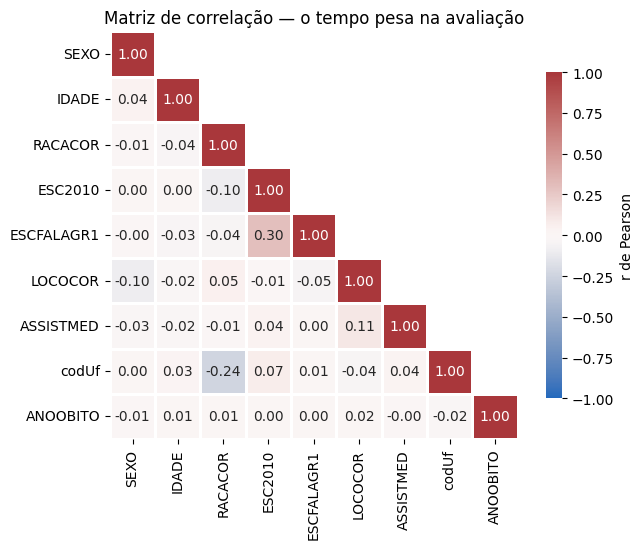

In [141]:
num = [
 
'SEXO',
'IDADE',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',

]
rotulos = [
 
'SEXO',
'IDADE',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',
]
corr = df[num].corr(method="pearson")
corr.index = corr.columns = rotulos
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white",
            cbar_kws=dict(label="r de Pearson", shrink=0.8), annot_kws=dict(size=10), ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação — o tempo pesa na avaliação")
fig.tight_layout()
fig.savefig("fig/heatmap_correlacao.png", dpi=200, bbox_inches="tight")
plt.show()

In [142]:
df

,CAUSABAS,DTOBITO,SEXO,IDADE,TIPOBITO,RACACOR,ESC2010,ESCFALAGR1,LOCOCOR,ASSISTMED,codUf,ANOOBITO,Capital,Sigla UF
0,infarto,2022-02-23,1,43,2,1.0,3.0,12.0,3,2.0,24,2022,Natal,RN
1,infarto,2022-06-10,1,41,2,1.0,5.0,8.0,3,1.0,35,2022,São Paulo,SP
2,infarto,2022-02-06,1,41,2,1.0,1.0,10.0,4,2.0,43,2022,Porto Alegre,RS
3,infarto,2022-04-06,1,30,2,4.0,5.0,8.0,3,2.0,35,2022,São Paulo,SP
4,infarto,2022-01-20,1,26,2,1.0,3.0,12.0,1,1.0,52,2022,Goiânia,GO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17772,infarto,2025-07-09,2,44,2,4.0,3.0,6.0,3,2.0,14,2025,Boa Vista,RR
17773,infarto,2025-07-14,1,33,2,1.0,2.0,11.0,1,1.0,35,2025,São Paulo,SP
17774,infarto,2025-07-11,1,43,2,1.0,1.0,2.0,3,2.0,17,2025,Palmas,TO
17775,infarto,2025-07-18,2,42,2,1.0,2.0,4.0,1,1.0,35,2025,São Paulo,SP


In [143]:
#df_natal['MESOBITO'] = df_natal['DTOBITO'].dt.month
#df_capitalx = df.loc[(df['IDADE'] <= 35)  & (df['Capital'] =='São Paulo')]


df_capital = df.groupby(['Capital'])['CAUSABAS'].count().sort_values(ascending=True).reset_index()

df_assistencia = df.groupby(['ASSISTMED'])['CAUSABAS'].count().reset_index()









### Total de mortes Por Ano:

<Figure size 2600x600 with 0 Axes>

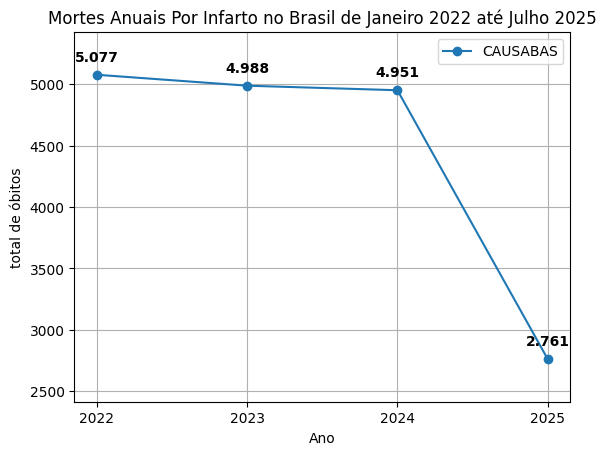

,index,CAUSABAS
0,mean,4444.250000
1,median,4969.500000
2,std,1123.411879


In [144]:
#Grafico de Linha de total de mortes por Estados.
df_anoobito = df.groupby(['ANOOBITO'])['CAUSABAS'].count().reset_index()


plt.figure(figsize=(26, 6))

# 3. Criar o gráfico de barras
ax = df_anoobito.plot(x = "ANOOBITO", y="CAUSABAS", kind="line",marker="o", 
         title="Mortes Anuais Por Infarto no Brasil de Janeiro 2022 até Julho 2025")

for x, y in zip(df_anoobito["ANOOBITO"], df_anoobito["CAUSABAS"]):
  ax.annotate(
      f"{int(y):,}".replace(",", "."),
      (x, y),
      textcoords="offset points",
      xytext=(0, 10),
      ha="center",
      fontsize=10,
      fontweight="bold",
  )
  # 5. Ajustar margem superior para o número não cortar no topo
ax.margins(y=0.15)


# 6. Ajustar grade e exibir
plt.xticks(df_anoobito["ANOOBITO"].astype(int))
plt.xlabel("Ano")
plt.ylabel("total de óbitos")
plt.grid(True)
plt.show()

ano_causa = df.groupby("ANOOBITO")["CAUSABAS"].count().reset_index()

df_resultado = ano_causa['CAUSABAS'].agg(['mean', 'median', 'std']).T.reset_index()
df_resultado

### Mortes por Sexo Geral e por Ano: 

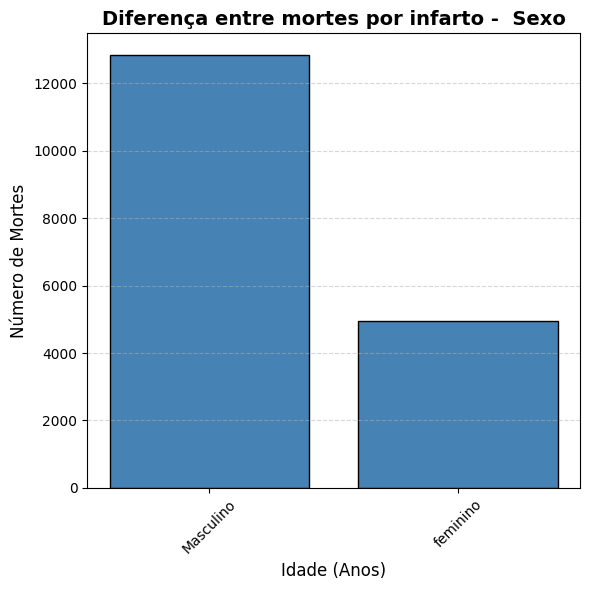

0    Masculino
1     feminino
Name: SEXO, dtype: object

In [145]:
df_agrupado = df.groupby(['SEXO'])['CAUSABAS'].count().reset_index()

plt.figure(figsize=(6, 6))
mapa_assistencia = {
    1.0: 'Masculino',
    2.0: 'feminino'
}
# 3. Criar o gráfico de barras
categoria = df_agrupado['SEXO'].map(mapa_assistencia)

categoria = categoria.astype(str)

barras = plt.bar(categoria, df_agrupado['CAUSABAS'], color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Diferença entre mortes por infarto -  Sexo', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
#for barra in barras:
#altura = barra.get_height()
#    plt.text(
 #       barra.get_x() + barra.get_width() / 2,
  #      altura + 10,  # Pequeno espaço acima da barra
   #     f'{int(altura)}',
    #    ha='center',
     #   va='bottom',
      #  fontsize=10
 #   )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("fig/grafico_barra_sexo.png", dpi=200, bbox_inches="tight")
plt.show()


df_agrupado['SEXO'].map(mapa_assistencia)

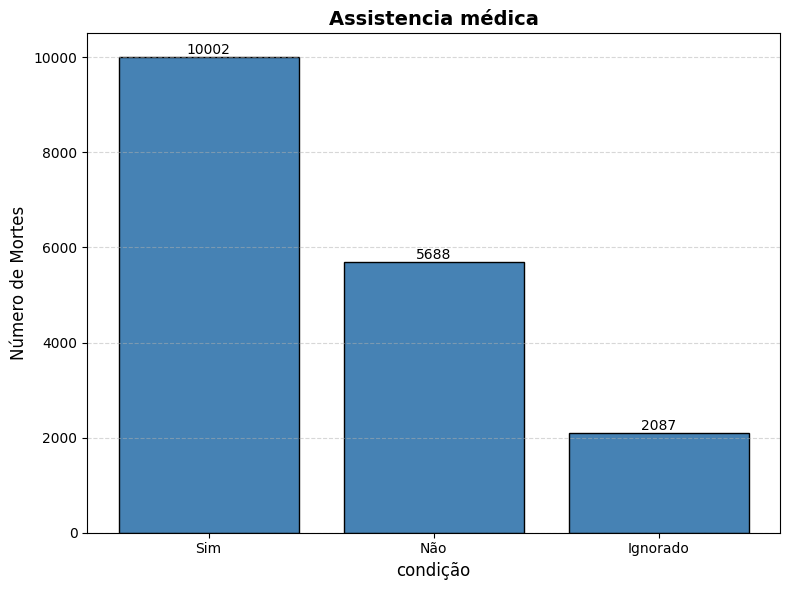

In [ ]:


mapa_assistencia = {
    1: 'Sim',
    2: 'Não',
    9: 'Ignorado'
}

plt.figure(figsize=(8, 6))



# Cria a série com os nomes (caso a coluna seja float, ex: 1.0, o map também funciona)
categorias = df_assistencia['ASSISTMED'].map(mapa_assistencia)
# 3. Criar o gráfico de barras
barras = plt.bar(categorias, df_assistencia['CAUSABAS'], color='steelblue', edgecolor='black')
descricoes = ["Com assistência (1)", "Sem assistência (2)", "Ignorado (9)"]
# 4. Adicionar títulos e rótulos nos eixos
plt.title('Assistencia médica', fontsize=14, fontweight='bold')
plt.xlabel('condição', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()    
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 10,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig.savefig("fig/grafico_barra_assist.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 600x600 with 0 Axes>

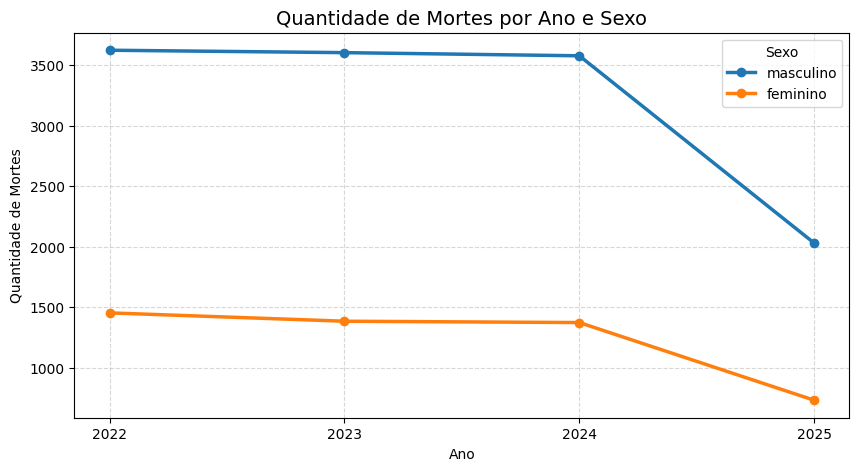

SEXO,1,2
ANOOBITO,,
2022,3624,1453
2023,3604,1384
2024,3578,1373
2025,2030,731


In [147]:
df_agrupado_ano = df.groupby(['ANOOBITO', 'SEXO']).size().unstack(fill_value=0)
plt.figure(figsize=(6, 6))
mapa_assistencia = {
    1.0: 'Masculino',
    2.0: 'feminino'
}
#categoria = df_agrupado_ano['SEXO'].map(mapa_assistencia)

# 2. Plota o gráfico
fig, ax = plt.subplots(figsize=(10, 5))

for sexo in df_agrupado_ano.columns:
    ax.plot(df_agrupado_ano.index, df_agrupado_ano[sexo], marker='o', linewidth=2.5, label=sexo)

ax.set_title('Quantidade de Mortes por Ano e Sexo', fontsize=14)
ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de Mortes')
ax.legend(title='Sexo', labels=['masculino','feminino'])
ax.set_xticks(df_agrupado_ano.index)
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()


df_agrupado_ano.head()

### Mortes por Infarto por Capitais

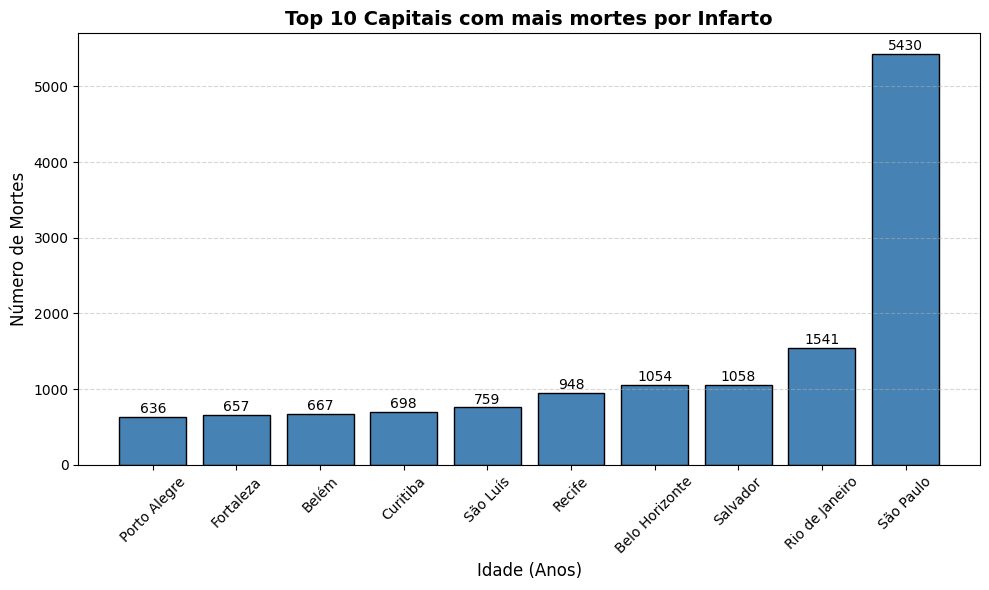

In [148]:
df_Capital = df.groupby(['ANOOBITO','Capital']).size().unstack(fill_value=0)

plt.figure(figsize=(10, 6))

# 3. Criar o gráfico de barras
barras = plt.bar(df_capital['Capital'].tail(10), df_capital['CAUSABAS'].tail(10), color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Top 10 Capitais com mais mortes por Infarto', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 10,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("fig/grafico_barra.png", dpi=200, bbox_inches="tight")
plt.show()



### Mortes por infartos nas Capitais por 100k Habitantes

In [ ]:
df_capital_anual = df.groupby(['ANOOBITO','Capital'])['CAUSABAS'].count().reset_index()


df_m100k_habitantes = pd.merge(
    df_capital,
    df_morte_capitais,
    left_on="Capital",
    right_on="Capital",
    how='left'
)   

df_m100k_habitantes['mortes_por_100K_habitantes'] = ((df_m100k_habitantes['CAUSABAS'] / df_m100k_habitantes['População Estimada (2026)'])*100000).round(2)

 
df_m100k_habitantes= df_m100k_habitantes.sort_values(by=['mortes_por_100K_habitantes'],ascending=True)



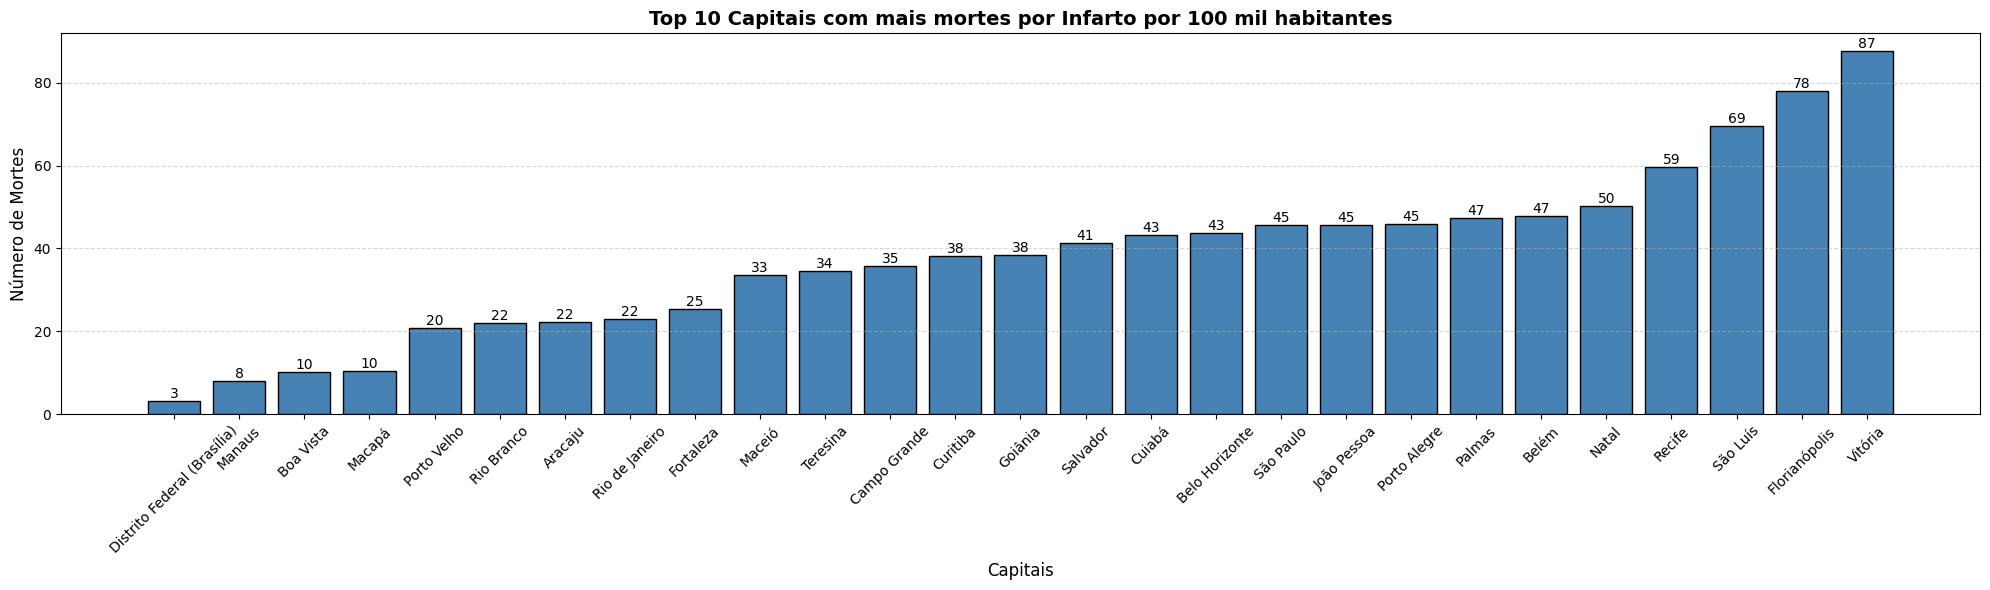

In [177]:
plt.figure(figsize=(20, 6))

# 3. Criar o gráfico de barras
barras = plt.bar(df_m100k_habitantes['Capital'], df_m100k_habitantes['mortes_por_100K_habitantes'], color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Top 10 Capitais com mais mortes por Infarto por 100 mil habitantes', fontsize=14, fontweight='bold')
plt.xlabel('Capitais', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura ,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("fig/grafico_barra.png", dpi=200, bbox_inches="tight")
plt.show()

In [179]:
df_m100k_habitantes['mortes_por_100K_habitantes'].agg(['mean','median','std'])

mean      38.189259
median    38.430000
std       20.543408
Name: mortes_por_100K_habitantes, dtype: float64

In [150]:
df_anoobito_media = df_anoobito['CAUSABAS'].mean()
df_anoobito_mediana = df_anoobito['CAUSABAS'].median()
df_anoobito_desvio = df_anoobito['CAUSABAS'].std()
porcentagemDesvioh = df_anoobito_desvio/df_anoobito_media * 100


df_capital_media = df_capital['CAUSABAS'].mean()
df_capital_mediana = df_capital['CAUSABAS'].median()
df_capital_desvio = df_capital['CAUSABAS'].std()
porcentagemDesviot = df_capital_desvio/df_capital_media * 100



print(f'media {df_anoobito_media}')
print(f'mediana {df_anoobito_mediana}')
print(f'desvio padrao {df_anoobito_desvio}')
print(f'porcentagem desvio {porcentagemDesvioh}')


print(f'media {df_capital_media}')
print(f'mediana {df_capital_mediana}')
print(f'desvio padrao {df_capital_desvio}')
print(f'porcentagem desvio {porcentagemDesviot}')





media 4444.25
mediana 4969.5
desvio padrao 1123.4118790541606
porcentagem desvio 25.277873185670487
media 658.4074074074074
mediana 393.0
desvio padrao 1021.5944648989886
porcentagem desvio 155.16144766986946


In [151]:
#prob_menor_30 = norm.cdf(18, loc=df_capital_media, scale=df_capital_desvio)
#print(f"Chance de ter até 30 mortes: {prob_menor_30:.2%}")



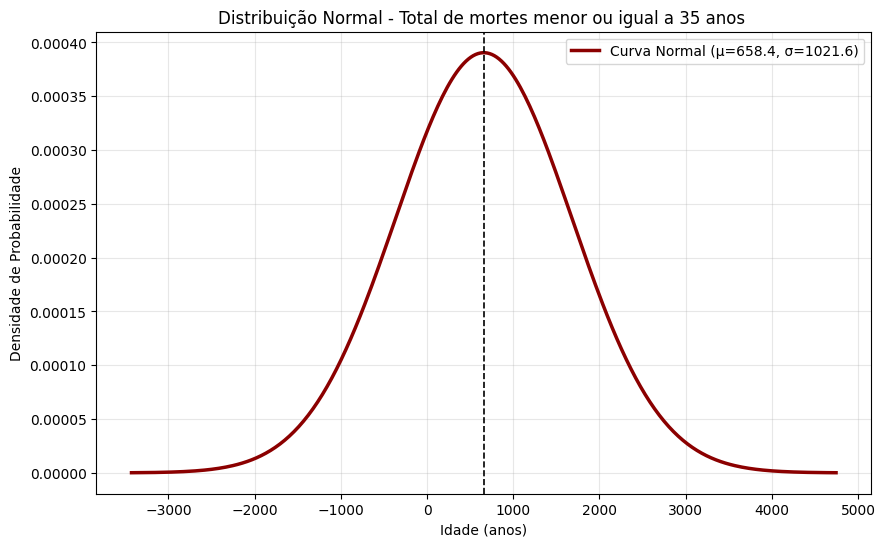

In [152]:
plt.figure(figsize=(10, 6))
dados = df_capital['CAUSABAS']

# 3. Calcular e desenhar uma curva para cada causa
media = df_capital_media
desvio = df_capital_desvio
x = np.linspace(media - 4 * desvio, media + 4 * desvio, 300)
y = norm.pdf(x, loc=media, scale=desvio)

plt.plot(
    x,
    y,
    color='darkred',
    linewidth=2.5,
    label=f'Curva Normal (μ={media:.1f}, σ={desvio:.1f})',
)

plt.axvline(media, color='black', linestyle='--', linewidth=1.2)

plt.title('Distribuição Normal - Total de mortes menor ou igual a 35 anos ')
plt.xlabel('Idade (anos)')
plt.ylabel('Densidade de Probabilidade')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [153]:
#INTERVALO DE CONFIANÇA
erro_padrao = stats.sem(dados)  
confianca = 0.95


ic_normal = stats.norm.interval(confianca, loc=media, scale=erro_padrao)

ic_t = stats.t.interval(
    confianca, df=len(dados) - 1, loc=media, scale=erro_padrao
)

print(f'Média amostral: {media:.2f}')
print(f'IC 95% (Normal): {ic_normal[0]:.2f} a {ic_normal[1]:.2f}')


Média amostral: 658.41
IC 95% (Normal): 273.07 a 1043.75


In [154]:
#P-VALOR (Teste de Hipotese)
valor_referencia = 886  # Hipótese nula (H0): média = 40

# Teste t de uma amostra (mais usado na prática)
estatistica_t, p_valor = stats.ttest_1samp(dados, popmean=valor_referencia, alternative='two-sided')

print(f'Estatística t: {estatistica_t:.4f}')
print(f'p-valor: {p_valor:.4f}')

# Interpretação automática (nível de significância alfa = 0.05)
if p_valor < 0.05:
  print(f'Resultado significativo: rejeitamos H0 (a média é diferente de {valor_referencia}.')
else:
  print(
      f'Não Rejeita H0 a média não difere de {valor_referencia}'
  )


Estatística t: -1.1576
p-valor: 0.2575
Não Rejeita H0 a média não difere de 886
